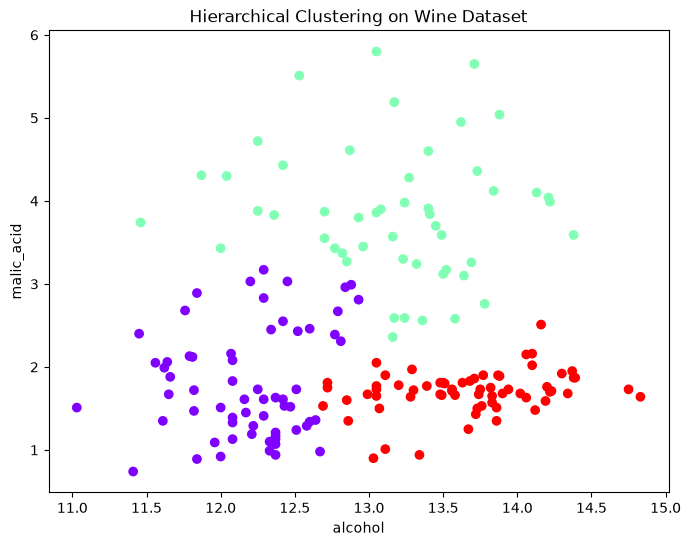

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.cluster import AgglomerativeClustering

wine = load_wine()
X = wine.data[:, :2]

model = AgglomerativeClustering(n_clusters=3)
labels = model.fit_predict(X)

plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c=labels, cmap="rainbow")
plt.xlabel(wine.feature_names[0])
plt.ylabel(wine.feature_names[1])
plt.title("Hierarchical Clustering on Wine Dataset")
plt.show()

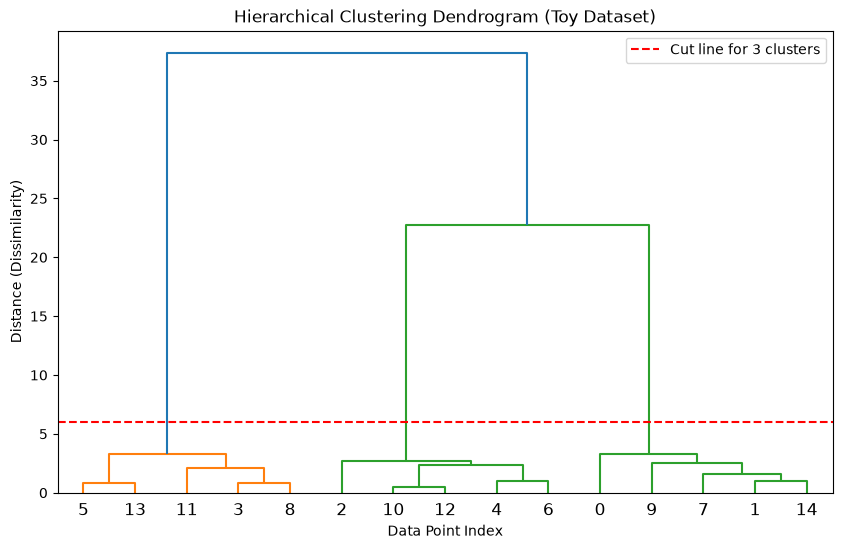

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.datasets import make_blobs

# 1. Create a synthetic toy dataset (3 distinct groups in 2D space)
X, y = make_blobs(n_samples=15, centers=3, random_state=42, cluster_std=1.0)

# 2. Perform Hierarchical Clustering
# 'ward' linkage minimizes the variance of clusters being merged
Z = linkage(X, method='ward')

# 3. Plot the Dendrogram
plt.figure(figsize=(10, 6))
plt.title("Hierarchical Clustering Dendrogram (Toy Dataset)")
plt.xlabel("Data Point Index")
plt.ylabel("Distance (Dissimilarity)")

# Draw the dendrogram
dendrogram(
    Z,
    labels=None,         # You can pass a list of strings if you want to name points
    leaf_rotation=0.,   # Rotates the x-axis labels
    leaf_font_size=12.,  # Font size for the x-axis labels
)

# Optional: Add a horizontal line to visualize a "cut" into 3 clusters
plt.axhline(y=6.0, color='r', linestyle='--', label='Cut line for 3 clusters')
plt.legend()

plt.show()


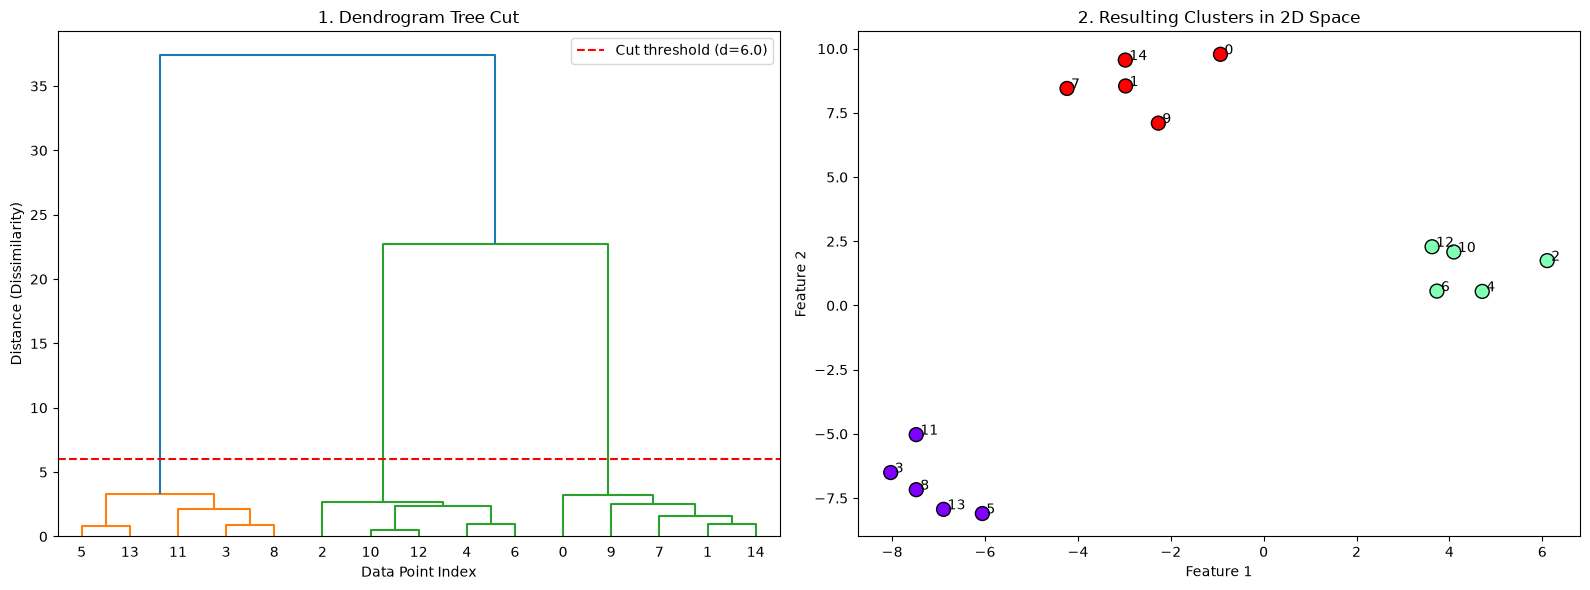

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.datasets import make_blobs

# 1. Generate the toy dataset (15 points across 3 natural groups)
X, y = make_blobs(n_samples=15, centers=3, random_state=42, cluster_std=1.0)

# 2. Compute the hierarchical clustering linkage matrix
Z = linkage(X, method='ward')

# 3. Cut the tree at a distance threshold of 6.0 to extract 3 clusters
max_d = 6.0
cluster_assignments = fcluster(Z, max_d, criterion='distance')

# 4. Set up a side-by-side plotting canvas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: The Dendrogram (The Tree)
ax1.set_title("1. Dendrogram Tree Cut")
ax1.set_xlabel("Data Point Index")
ax1.set_ylabel("Distance (Dissimilarity)")
dendrogram(Z, ax=ax1, leaf_rotation=0., leaf_font_size=10.)
ax1.axhline(y=max_d, color='r', linestyle='--', label=f'Cut threshold (d={max_d})')
ax1.legend()

# Plot 2: The Scatter Plot (The Resulting Clusters)
ax2.set_title("2. Resulting Clusters in 2D Space")
ax2.set_xlabel("Feature 1")
ax2.set_ylabel("Feature 2")

# Scatter plot color-coded by the extracted cluster assignments
scatter = ax2.scatter(X[:, 0], X[:, 1], c=cluster_assignments, cmap='rainbow', s=100, edgecolors='k')

# Label each individual point with its index so you can trace it back to the dendrogram
for i, txt in enumerate(range(len(X))):
    ax2.annotate(f" {i}", (X[i, 0], X[i, 1]))

plt.tight_layout()
plt.show()

